## 1 Two catalogues: uniform and structured

El catálogo estructurado va a tener preferencia por una separación de la escala de radio, es decir, una separación de 30. A esta distancia yo espero que este catálogo presenta más pares que el catálogo uniforme por la densidad de puntos que pueden existir.

A separaciones más pequeñas de 30 en el estructurado, yo esperaría que sea menos probable encontrar pares en el catálogo uniforme.

Sí, la función de correlación puede llegar a valer cero en el catálogo uniforme para algunos casos. Volviendo a la comparación, si escogemos un radio menor a la distancia mínima de separación entre puntos en el catálogo uniforme, entonces la función de correlación siempre será cero en ese caso.

In [17]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['font.size'] = 14
SEED = 42
rng = np.random.default_rng(SEED)

In [18]:
NR = 1000
ND = 1000
radius = 30

x_grid, y_grid = np.meshgrid(np.linspace(0, 99, 100), np.linspace(0, 99, 100))

centers = rng.uniform(0, 100, size=(20, 2))
xy_unif = rng.uniform(0, 100, size=(NR, 2))
xy_strc = np.zeros((ND, 2))
for i in range(ND):
    while True:
        p = centers[rng.choice(range(20))]
        angle = rng.uniform(0, 2*np.pi)
        X = p[0] + radius * np.cos(angle)
        Y = p[1] + radius * np.sin(angle)
        if 0 <= X < 100 and 0 <= Y < 100:
            break
    xy_strc[i] = [X, Y]


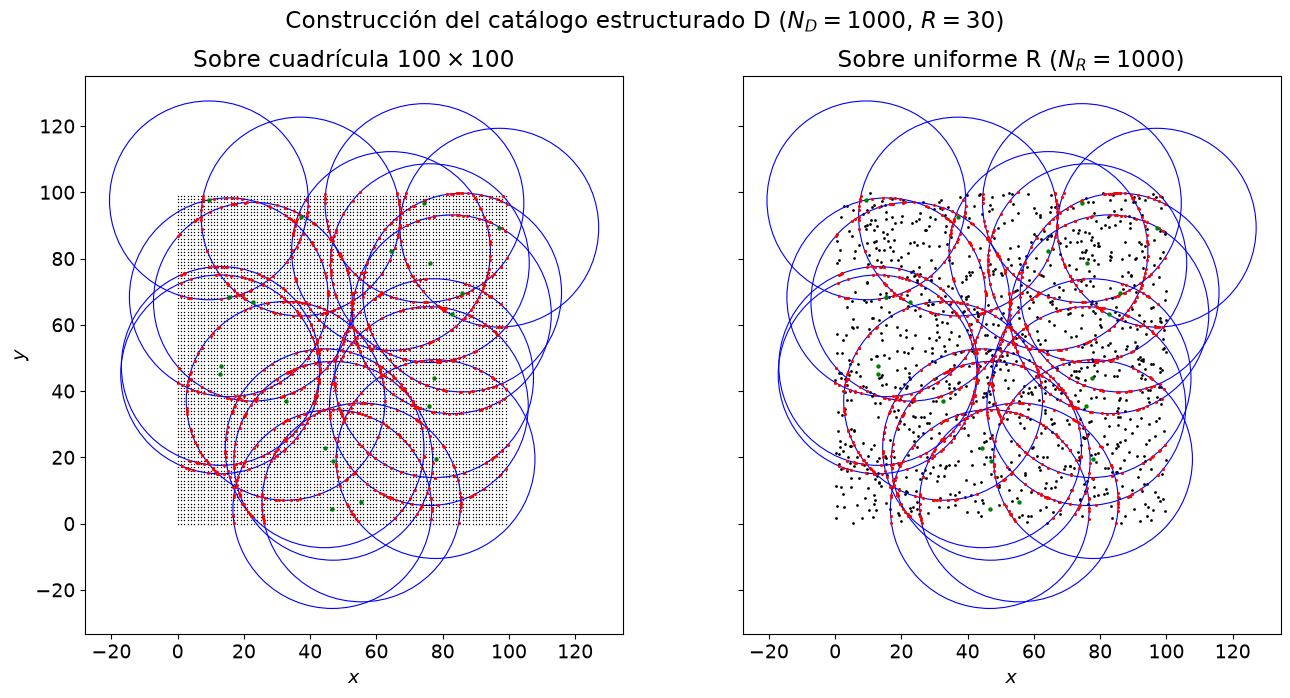

In [19]:
fig, axs = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
fondos = [((x_grid, y_grid), 1, 'Sobre cuadrícula $100\\times100$'),
          (xy_unif.T, 4, f'Sobre uniforme R ($N_R={NR}$)')]
for ax, (fondo, s, titulo) in zip(axs, fondos):
    ax.scatter(*fondo, s=s, c='k', linewidths=0, zorder=1)
    for p in centers:
        ax.add_patch(plt.Circle(p, radius, fill=False, ec='b', lw=0.8, zorder=2))
    ax.scatter(*xy_strc.T, s=5, c='r', linewidths=0, zorder=3)
    ax.scatter(*centers.T, s=10, c='g', linewidths=0, zorder=4)
    ax.set(xlabel='$x$', title=titulo, aspect='equal')
axs[0].set_ylabel('$y$')
fig.suptitle(f'Construcción del catálogo estructurado D ($N_D={ND}$, $R={radius}$)')
fig.tight_layout()
plt.show()

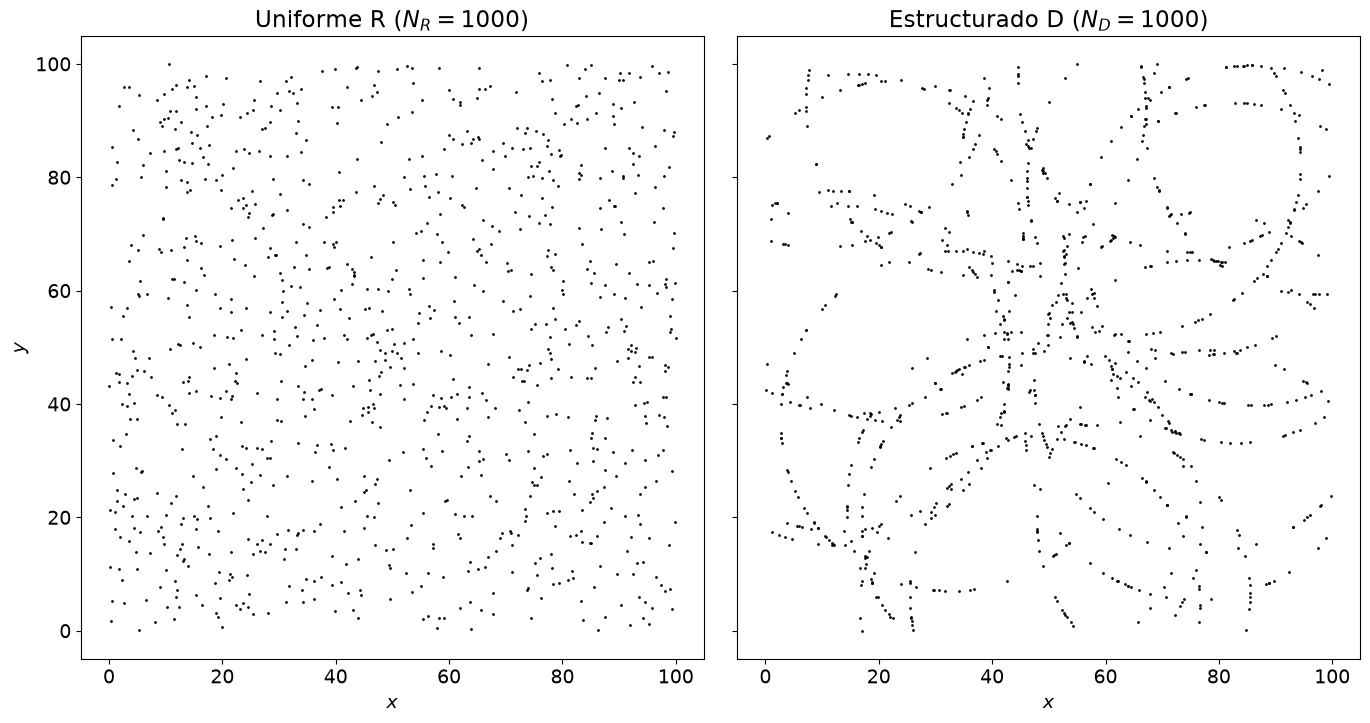

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)
ax1.scatter(*xy_unif.T, s=4, c='k', linewidths=0)
ax2.scatter(*xy_strc.T, s=4, c='k', linewidths=0)
ax1.set(xlabel='$x$', ylabel='$y$', title=f'Uniforme R ($N_R={NR}$)', aspect='equal')
ax2.set(xlabel='$x$', title=f'Estructurado D ($N_D={ND}$)', aspect='equal')
fig.tight_layout()
plt.show()

## 2 Compute pairs

In [21]:
edges = np.linspace(0, 100*np.sqrt(2), 51)
DD = np.zeros(len(edges) - 1, dtype=int)
RR = np.zeros(len(edges) - 1, dtype=int)
DR = np.zeros(len(edges) - 1, dtype=int)
for i in range(ND - 1):
    dd = np.linalg.norm(xy_strc[i+1:] - xy_strc[i], axis=1)
    DD += np.histogram(dd, bins=edges)[0]
for i in range(NR - 1):
    rr = np.linalg.norm(xy_unif[i+1:] - xy_unif[i], axis=1)
    RR += np.histogram(rr, bins=edges)[0]
for i in range(NR):
    dr = np.linalg.norm(xy_strc - xy_unif[i], axis=1)
    DR += np.histogram(dr, bins=edges)[0]

DD_norm = DD / (ND * (ND - 1) / 2)
RR_norm = RR / (NR * (NR - 1) / 2)
DR_norm = DR / (ND * NR)

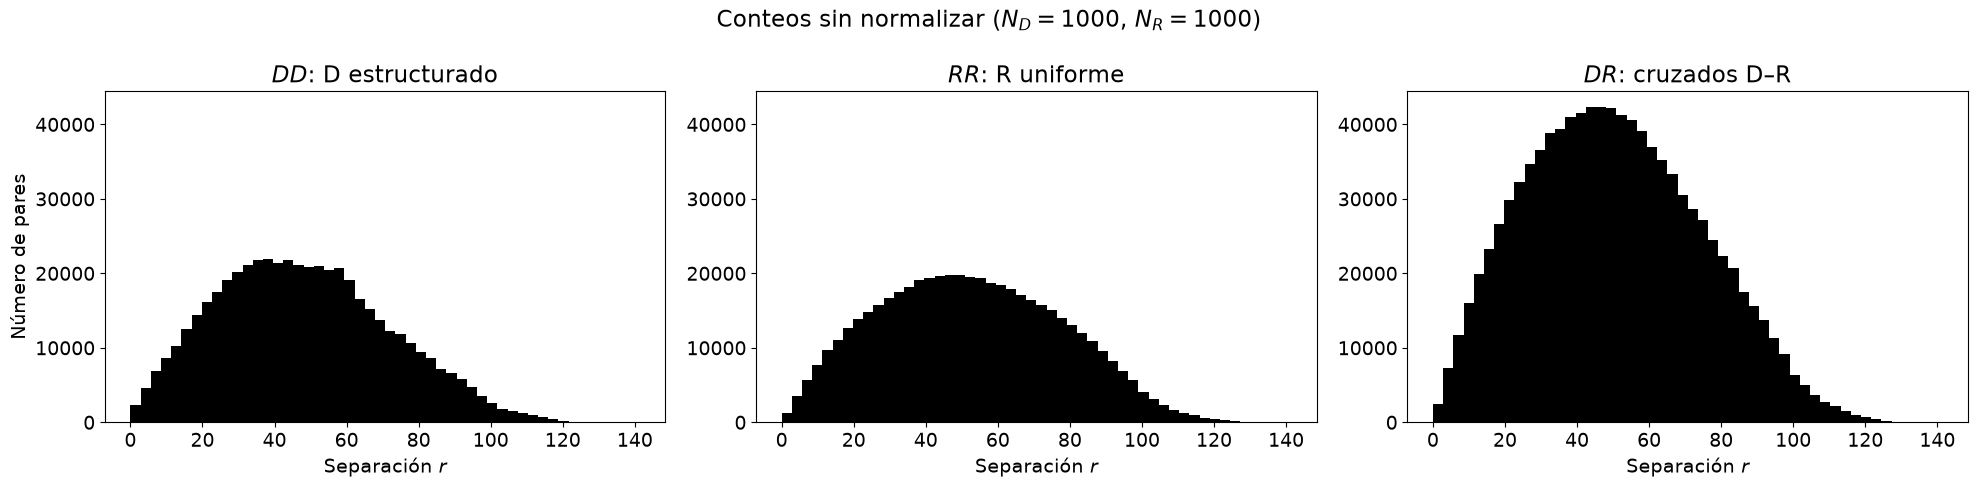

In [22]:
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
datos = [(DD, '$DD$: D estructurado'), (RR, '$RR$: R uniforme'), (DR, '$DR$: cruzados D–R')]
top = 1.05 * max(DD.max(), RR.max(), DR.max())
for ax, (H, t) in zip(axs, datos):
    ax.stairs(H, edges, fill=True, color='k')
    ax.set(xlabel='Separación $r$', title=t, ylim=(0, top))
axs[0].set_ylabel('Número de pares')
fig.suptitle(f'Conteos sin normalizar ($N_D={ND}$, $N_R={NR}$)')
fig.tight_layout()
plt.show()

La idea de que cerca del límite $100\sqrt{2}$ hay pocos para viene a que existen relaticamente pocos puntos que caen cerca de las esquinas debido a que están uniformemente distribuidos. Para que uno de estos pares cuenta, los puntos deben estar en esquinas diametralmente opuestas.

In [23]:
mask_RR = RR_norm == 0   # denominador de PH y LS
mask_DR = DR_norm == 0   # denominador de DP y H
with np.errstate(divide='ignore', invalid='ignore'):
    XPH = DD_norm / RR_norm - 1
    XDP = DD_norm / DR_norm - 1
    XH = DD_norm * RR_norm / DR_norm ** 2 - 1
    XLS = (DD_norm - 2 * DR_norm + RR_norm) / RR_norm
XPH[mask_RR] = np.nan
XLS[mask_RR] = np.nan
XDP[mask_DR] = np.nan
XH[mask_DR] = np.nan
print('Bins con RR = 0 (PH, LS):', np.flatnonzero(mask_RR))
print('Bins con DR = 0 (DP, H): ', np.flatnonzero(mask_DR))

Bins con RR = 0 (PH, LS): [49]
Bins con DR = 0 (DP, H):  [49]


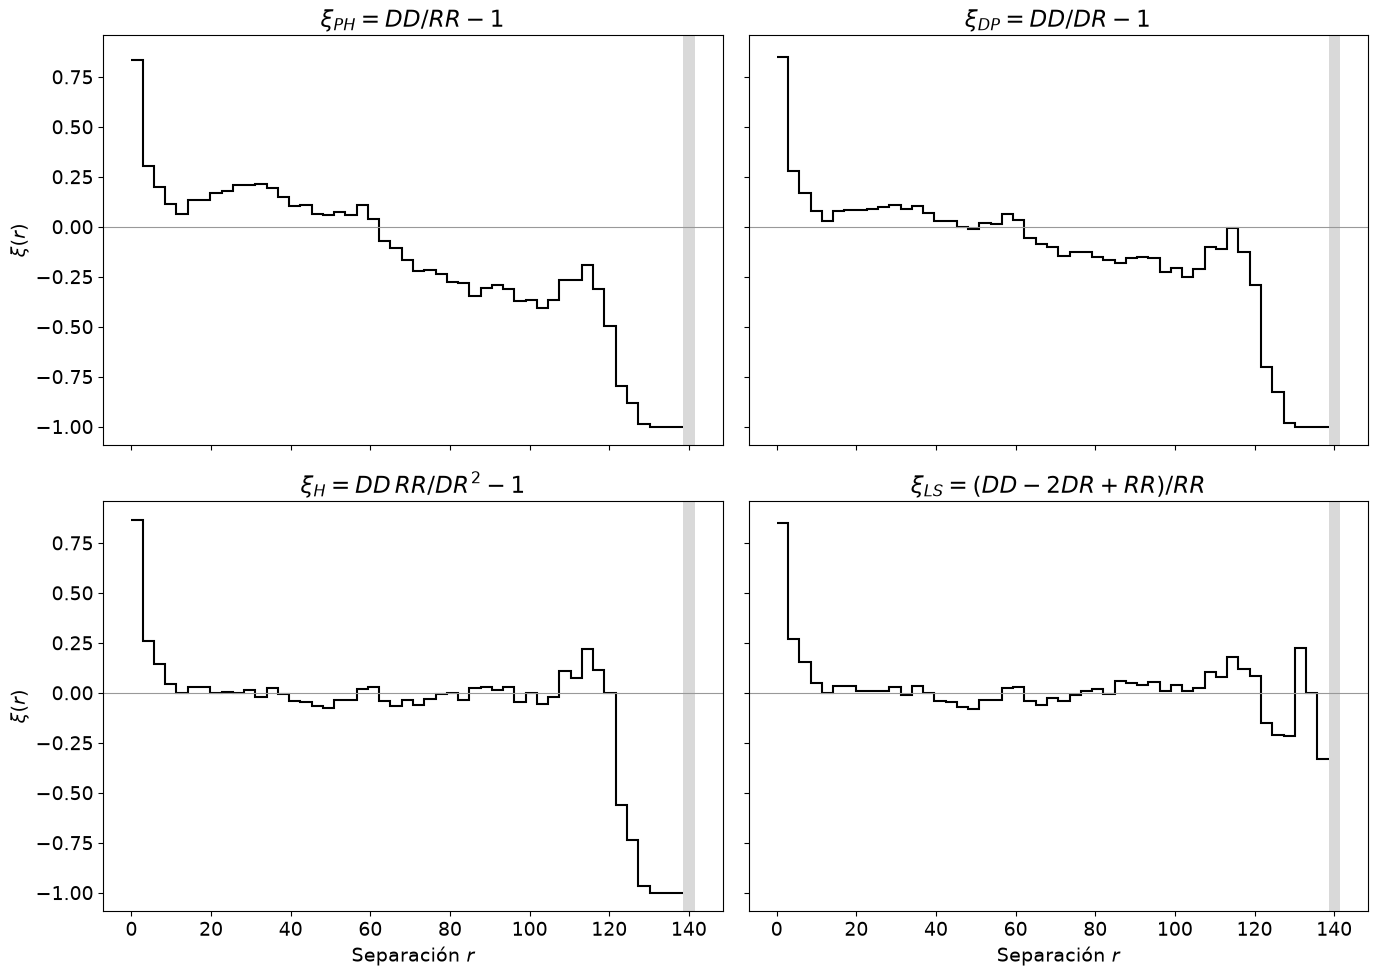

In [24]:
xis = [(XPH, mask_RR, r'$\xi_{PH} = DD/RR - 1$'), (XDP, mask_DR, r'$\xi_{DP} = DD/DR - 1$'),
       (XH, mask_DR, r'$\xi_{H} = DD\,RR/DR^2 - 1$'), (XLS, mask_RR, r'$\xi_{LS} = (DD - 2DR + RR)/RR$')]

fig, axs = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
for ax, (xi, m, t) in zip(axs.flat, xis):
    ax.stairs(xi, edges, color='k', lw=1.5, baseline=None)
    ax.axhline(0, color='0.6', lw=0.8)
    for a, b in zip(edges[:-1][m], edges[1:][m]):
        ax.axvspan(a, b, color='0.85', lw=0)
    ax.set(title=t)
for ax in axs[:, 0]:
    ax.set_ylabel(r'$\xi(r)$')
for ax in axs[1]:
    ax.set_xlabel('Separación $r$')
fig.tight_layout()
plt.show()

### Comparación de reglas de binning

In [25]:
from scipy.spatial.distance import pdist

def pair_counts(A, B=None, edges=edges):
    H = np.zeros(len(edges) - 1, dtype=int)
    if B is None:
        for i in range(len(A) - 1):
            H += np.histogram(np.linalg.norm(A[i+1:] - A[i], axis=1), bins=edges)[0]
    else:
        for i in range(len(B)):
            H += np.histogram(np.linalg.norm(A - B[i], axis=1), bins=edges)[0]
    return H

def plot_counts(edges, regla):
    h = np.diff(edges)
    H = (pair_counts(xy_strc, edges=edges) / (ND * (ND - 1) / 2) / h,
         pair_counts(xy_unif, edges=edges) / (NR * (NR - 1) / 2) / h,
         pair_counts(xy_strc, xy_unif, edges) / (ND * NR) / h)
    fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
    for ax, Hi, t in zip(axs, H, ('$DD$', '$RR$', '$DR$')):
        ax.stairs(Hi, edges, fill=True, color='k')
        ax.set(xlabel='Separación $r$', title=t)
    axs[0].set_ylabel('Fracción de pares / $h$')
    fig.suptitle(f'{regla}: {len(h)} bins, $h = {h[0]:.2f}$')
    fig.tight_layout()
    plt.show()

# Distancias RR solo para elegir el ancho; los mismos edges se usan en DD, RR y DR
r_ref = pdist(xy_unif)
rango = (0, 100*np.sqrt(2))

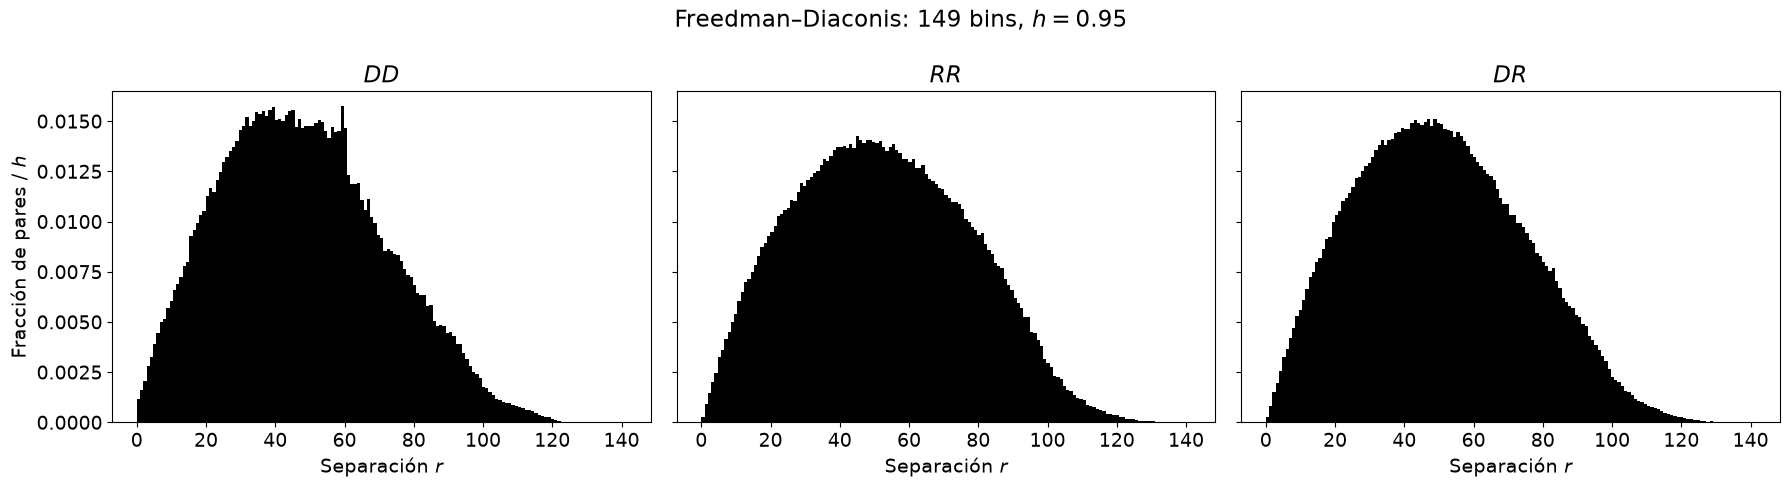

In [26]:
edges_fd = np.histogram_bin_edges(r_ref, bins='fd', range=rango)
plot_counts(edges_fd, 'Freedman–Diaconis')

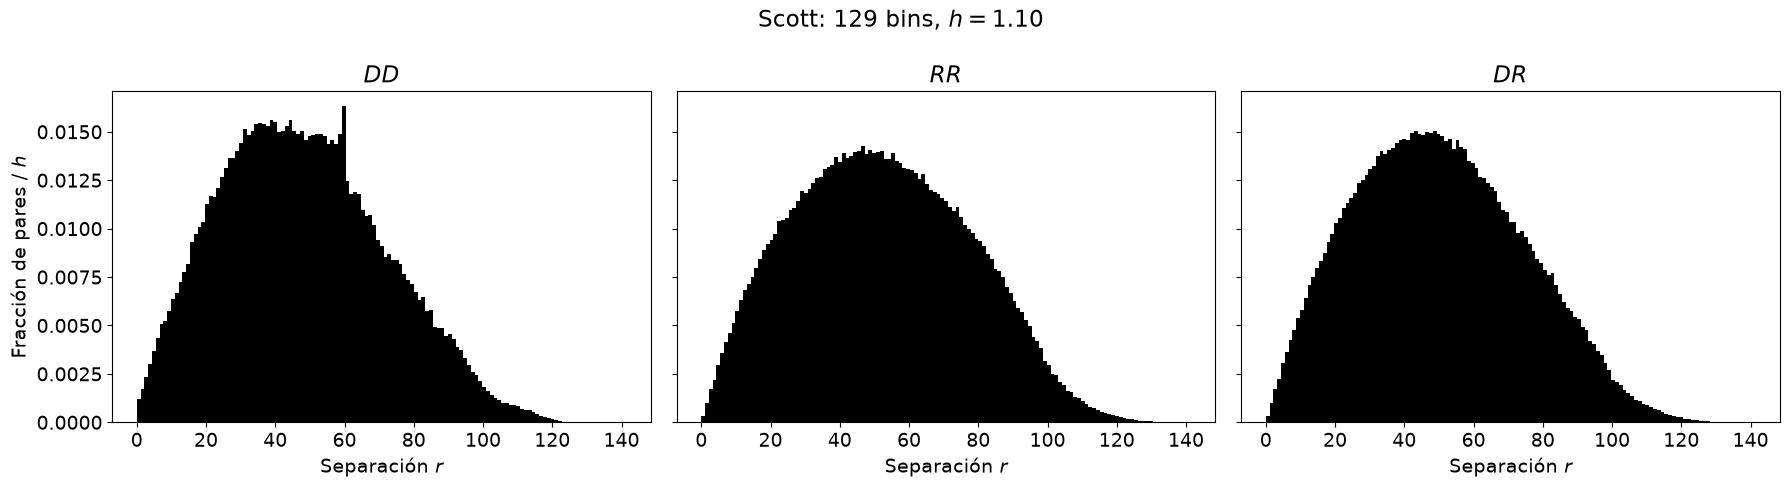

In [27]:
edges_scott = np.histogram_bin_edges(r_ref, bins='scott', range=rango)
plot_counts(edges_scott, 'Scott')

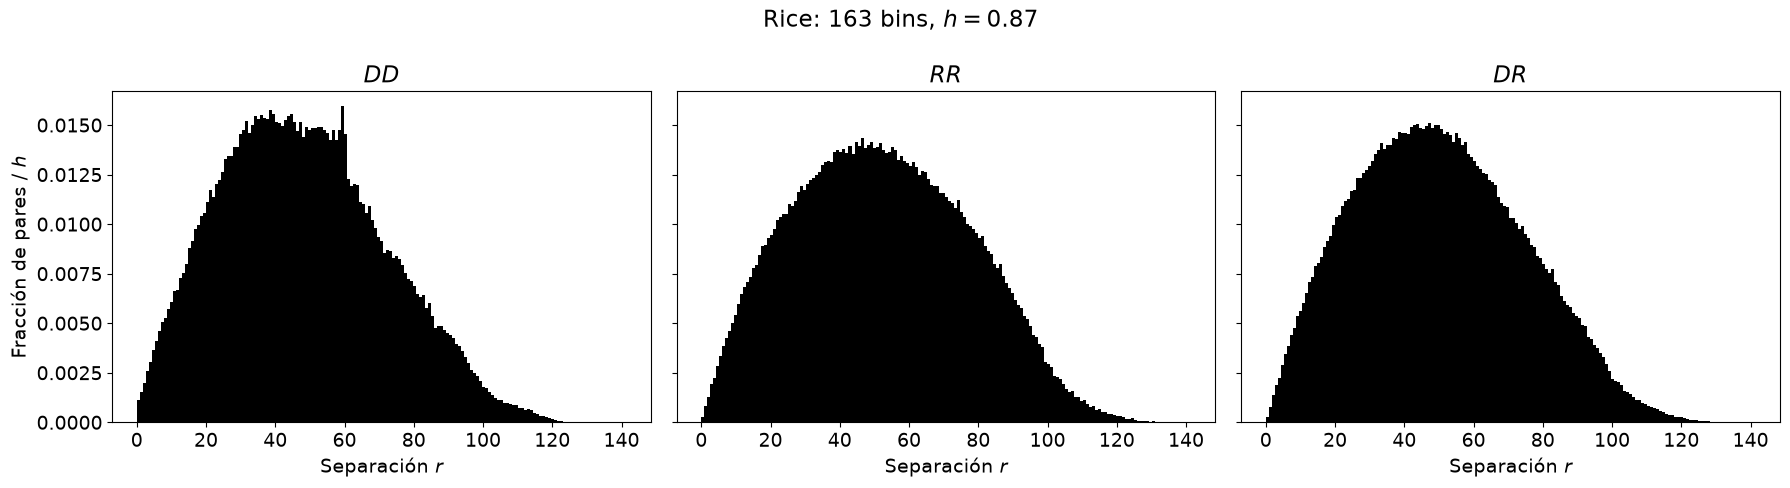

In [28]:
edges_rice = np.histogram_bin_edges(r_ref, bins='rice', range=rango)
plot_counts(edges_rice, 'Rice')

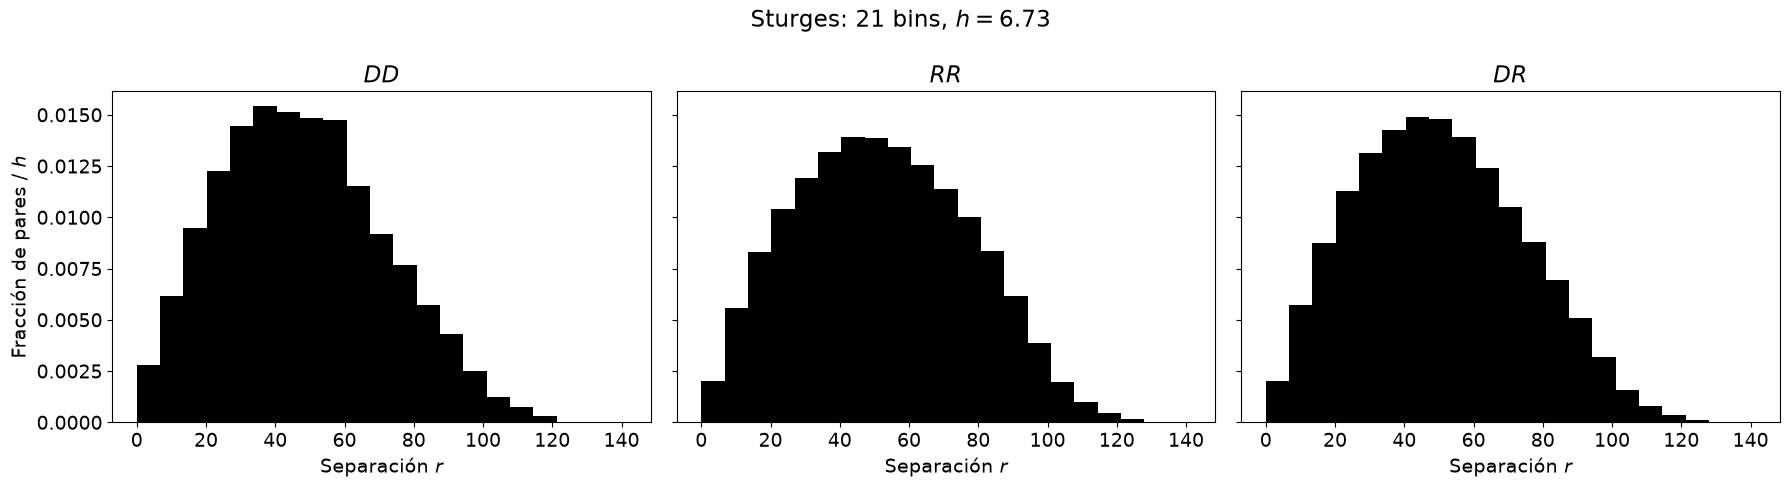

In [29]:
edges_sturges = np.histogram_bin_edges(r_ref, bins='sturges', range=rango)
plot_counts(edges_sturges, 'Sturges')